In [ ]:
# Mount Google Drive to access your files
from google.colab import drive
drive.mount('/content/drive')


In [ ]:
# Check GPU availability and install required packages
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")

# Install required packages for YOLOv8 training
!pip install ultralytics
!pip install albumentations

# Verify installation
import ultralytics
print(f"Ultralytics version: {ultralytics.__version__}")
print("Setup complete!")


In [ ]:
# Check if your files are accessible in Google Drive
import os

drive_path = '/content/drive/MyDrive/YOLOv8_Training'
print("📁 Files in your YOLOv8_Training folder:")
print("="*50)

if os.path.exists(drive_path):
    files = os.listdir(drive_path)
    for file in files:
        file_path = os.path.join(drive_path, file)
        if os.path.isfile(file_path):
            size = os.path.getsize(file_path) / (1024**3)  # Size in GB
            print(f"✅ {file} ({size:.2f} GB)")
        else:
            print(f"📁 {file} (folder)")
    print(f"\n📊 Total files found: {len(files)}")
else:
    print("❌ YOLOv8_Training folder not found!")
    print("Available folders in your Drive:")
    available = os.listdir('/content/drive/MyDrive/')
    for folder in available:
        print(f"  📁 {folder}")


In [ ]:
# Extract your dataset from the uploaded zip file
import zipfile
import os
import time

# Path to your uploaded zip file
zip_path = '/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'
extract_path = '/content/'

print("🚀 Starting dataset extraction...")
print("This may take 5-15 minutes depending on dataset size...")
print("="*60)

start_time = time.time()

try:
    # Check if zip file exists
    if not os.path.exists(zip_path):
        print("❌ Zip file not found at:", zip_path)
        print("Available files:")
        print(os.listdir('/content/drive/MyDrive/YOLOv8_Training/'))
    else:
        # Extract the dataset
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            print("📦 Extracting files...")
            zip_ref.extractall(extract_path)

        extraction_time = time.time() - start_time
        print(f"✅ Dataset extracted successfully in {extraction_time:.1f} seconds!")

        # Verify extraction
        if os.path.exists('/content/combined_classroom_dataset'):
            print("✅ Dataset folder created successfully")
            print("\n📁 Dataset structure:")
            print("combined_classroom_dataset/")
            print("├── images/")
            print("│   ├── train/")
            print("│   ├── valid/")
            print("│   └── test/")
            print("└── labels/")
            print("    ├── train/")
            print("    ├── valid/")
            print("    └── test/")
        else:
            print("❌ Dataset folder not found after extraction")
            print("Contents of /content/:")
            print(os.listdir('/content/'))

except zipfile.BadZipFile:
    print("❌ The zip file appears to be corrupted. Please re-upload.")
except Exception as e:
    print(f"❌ Error during extraction: {e}")
    print("Please check your zip file and try again.")


🚀 Starting dataset extraction...
This may take 5-15 minutes depending on dataset size...
📦 Extracting files...


KeyboardInterrupt: 

In [ ]:
# Count your dataset files and verify structure
import os

def count_files(directory, extension):
    if os.path.exists(directory):
        files = [f for f in os.listdir(directory) if f.endswith(extension)]
        return len(files)
    return 0

# Paths to your dataset folders
base_path = '/content/combined_classroom_dataset'
img_train = f'{base_path}/images/train'
img_valid = f'{base_path}/images/valid'
img_test = f'{base_path}/images/test'
lbl_train = f'{base_path}/labels/train'
lbl_valid = f'{base_path}/labels/valid'
lbl_test = f'{base_path}/labels/test'

# Count files in each split
train_images = count_files(img_train, '.jpg')
train_labels = count_files(lbl_train, '.txt')
valid_images = count_files(img_valid, '.jpg')
valid_labels = count_files(lbl_valid, '.txt')
test_images = count_files(img_test, '.jpg')
test_labels = count_files(lbl_test, '.txt')

print("📊 DATASET STATISTICS")
print("="*50)
print(f"Training:   {train_images:,} images, {train_labels:,} labels")
print(f"Validation: {valid_images:,} images, {valid_labels:,} labels")
print(f"Testing:    {test_images:,} images, {test_labels:,} labels")
print("="*50)
print(f"TOTAL:      {train_images + valid_images + test_images:,} images")

# Verify label-image matching
print(f"\n🔍 DATASET INTEGRITY CHECK")
print("="*50)
if train_images == train_labels:
    print("✅ Training set: Images and labels match")
else:
    print(f"⚠️  Training set: {train_images} images vs {train_labels} labels")

if valid_images == valid_labels:
    print("✅ Validation set: Images and labels match")
else:
    print(f"⚠️  Validation set: {valid_images} images vs {valid_labels} labels")

if test_images == test_labels:
    print("✅ Test set: Images and labels match")
else:
    print(f"⚠️  Test set: {test_images} images vs {test_labels} labels")

# Check if total matches your expected ~32,437 images
expected_total = 32437
if abs((train_images + valid_images + test_images) - expected_total) < 1000:
    print(f"\n✅ Dataset size looks correct! (~{expected_total:,} expected)")
else:
    print(f"\n⚠️  Dataset size differs from expected {expected_total:,}")


In [ ]:
# Create optimized YAML configuration for Colab training
yaml_content = """
# Classroom Behavior Detection Dataset Configuration
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

# Class names for classroom behavior detection
names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9  # number of classes
"""

# Save the configuration file
config_path = '/content/classroom_combined_colab.yaml'
with open(config_path, 'w') as f:
    f.write(yaml_content)

print("✅ Colab-optimized YAML configuration created!")
print(f"📄 Configuration saved as: {config_path}")
print(f"📊 Training with {32437 + 2740 + 1325:,} total images")

# Display the configuration
print("\n📋 Configuration contents:")
print("="*40)
with open(config_path, 'r') as f:
    print(f.read())


In [ ]:
# Copy your optimized training script from Google Drive
import shutil
import os

# Source path in Google Drive
source_script = '/content/drive/MyDrive/YOLOv8_Training/train_optimized.py'
# Destination path in Colab
dest_script = '/content/train_optimized.py'

print("📥 Loading your optimized training script...")

try:
    if os.path.exists(source_script):
        shutil.copy(source_script, dest_script)
        print("✅ Training script loaded successfully!")

        # Check script size
        script_size = os.path.getsize(dest_script) / 1024  # Size in KB
        print(f"📄 Script size: {script_size:.1f} KB")

        # Verify the script exists in Colab
        if os.path.exists(dest_script):
            print("✅ Script ready for execution in Colab")

    else:
        print("❌ Training script not found in Google Drive")
        print("Available files in YOLOv8_Training:")
        drive_files = os.listdir('/content/drive/MyDrive/YOLOv8_Training/')
        for file in drive_files:
            print(f"  📄 {file}")

except Exception as e:
    print(f"❌ Error loading training script: {e}")

print("\n🎯 Focus classes for this training:")
print("  1. Sleeping detection")
print("  2. Phone usage detection")
print("  3. No ID card detection")
print("  4. Plus 6 additional behavior classes")

print(f"\n📊 Ready to train with {36502:,} total images!")


In [ ]:
# Run this final verification cell
print("📋 FINAL SESSION SUMMARY")
print("="*50)
print("✅ Dataset: 36,502 images extracted and verified")
print("✅ Training script: Loaded (19.4 KB)")
print("✅ YAML config: Created in /content/classroom_combined_colab.yaml")
print("✅ Google Drive: All files backed up")
print("\n🎯 Ready for overnight training restart")
print("="*50)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


In [ ]:
!pip install ultralytics
!pip install albumentations

import torch
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU device: {torch.cuda.get_device_name(0)}")


In [ ]:
import zipfile
import os

# Extract your dataset
zip_path = '/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

# Verify extraction
if os.path.exists('/content/combined_classroom_dataset'):
    print("✅ Dataset extracted successfully!")
    print("📊 Ready for training with 36,502 total images")
else:
    print("❌ Dataset extraction failed")


In [ ]:
yaml_content = """
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9
"""

with open('/content/classroom_combined_colab.yaml', 'w') as f:
    f.write(yaml_content)

print("✅ Configuration created successfully!")


In [ ]:
# Copy and execute your optimized training script
import shutil

# Copy training script from Google Drive
shutil.copy('/content/drive/MyDrive/YOLOv8_Training/train_optimized.py', '/content/')

print("🚀 STARTING OPTIMIZED YOLOV8 TRAINING")
print("="*60)
print("🎯 Focus: sleeping, phone_usage, no_id_card detection")
print("📊 Dataset: 36,502 total images")
print("⏱️  Expected time: 10-16 hours")
print("🔥 Using Tesla T4 GPU")
print("="*60)

# Execute the optimized training
exec(open('/content/train_optimized.py').read())


In [ ]:
# Fix the YAML file path issue - copy from your Google Drive
import shutil
import os

# Copy the YAML file from Google Drive to the expected location
drive_yaml = '/content/drive/MyDrive/YOLOv8_Training/classroom_combined.yaml'
local_yaml = '/content/classroom_combined.yaml'

if os.path.exists(drive_yaml):
    shutil.copy(drive_yaml, local_yaml)
    print("✅ YAML configuration copied from Google Drive!")
    print(f"📄 Available at: {local_yaml}")

    # Verify the configuration
    with open(local_yaml, 'r') as f:
        print("\n📋 Configuration contents:")
        print("="*40)
        print(f.read())
else:
    print("❌ YAML file not found in Google Drive")
    print("Available files:")
    print(os.listdir('/content/drive/MyDrive/YOLOv8_Training/'))


In [ ]:
# Restart the optimized training with proper configuration
print("🚀 RESTARTING OPTIMIZED YOLOV8 TRAINING")
print("="*60)
print("🎯 Focus: sleeping, phone_usage, no_id_card detection")
print("📊 Dataset: 36,502 total images")
print("⏱️  Expected time: 10-16 hours")
print("🔥 Using Tesla T4 GPU")
print("="*60)

# Execute the training script
exec(open('/content/train_optimized.py').read())


In [ ]:
# Stop current training first, then run this optimized approach
from ultralytics import YOLO
import torch

print("🚀 OPTIMIZED YOLOV8M TRAINING FOR MAXIMUM mAP")
print("="*60)
print("🎯 Target: 0.87-0.92 mAP (from 0.72 baseline)")
print("⏱️  Expected time: 8-12 hours")
print("🔥 Using Tesla T4 GPU efficiently")
print("="*60)

# Load YOLOv8 Medium model (optimal balance)
model = YOLO('yolov8m.pt')

# Optimized training for high mAP in reasonable time
results = model.train(
    data='/content/classroom_combined.yaml',
    epochs=150,  # Increased epochs for better convergence
    imgsz=640,
    batch=24,    # Optimal batch size for T4
    device=0,
    amp=True,

    # Optimized hyperparameters for mAP
    patience=25,
    optimizer='AdamW',
    lr0=0.002,   # Higher initial learning rate
    lrf=0.01,    # Lower final learning rate
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=5,

    # Enhanced loss weights for better detection
    box=7.5,     # Higher box loss weight
    cls=2.0,     # Higher classification weight
    dfl=1.8,     # Distribution focal loss

    # Balanced augmentation for quality without speed penalty
    hsv_h=0.02,
    hsv_s=0.7,
    hsv_v=0.5,
    degrees=12.0,
    translate=0.1,
    scale=0.8,
    shear=2.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.15,
    copy_paste=0.2,

    # Training efficiency
    cos_lr=True,
    close_mosaic=10,
    save=True,
    save_period=10,
    plots=True,
    name='classroom_optimized_yolov8m',
    exist_ok=True,
    pretrained=True,
    verbose=True
)


In [ ]:
# Step 1: Install required packages (must be done first)
!pip install ultralytics
!pip install albumentations

# Verify installation and GPU access
import torch
print(f"✅ CUDA available: {torch.cuda.is_available()}")
print(f"🎯 GPU device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")

# Confirm ultralytics is working
from ultralytics import YOLO
print("✅ Ultralytics installed successfully!")
print("✅ Ready for YOLOv8m training!")


In [ ]:
# Step 2: Mount Google Drive to access your dataset
from google.colab import drive
drive.mount('/content/drive')

# Verify your dataset is accessible
import os
if os.path.exists('/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'):
    print("✅ Dataset found in Google Drive")
else:
    print("❌ Dataset not found - check Google Drive path")


In [ ]:
# Step 3: Extract your dataset
import zipfile
import os

print("📦 Extracting dataset from Google Drive...")

# Extract the dataset
zip_path = '/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("✅ Dataset extracted successfully!")

# Verify extraction
if os.path.exists('/content/combined_classroom_dataset'):
    print("✅ Dataset ready for training")

    # Quick dataset verification
    train_images = len([f for f in os.listdir('/content/combined_classroom_dataset/images/train') if f.endswith('.jpg')])
    print(f"📊 Training images found: {train_images:,}")
else:
    print("❌ Dataset extraction failed")


In [ ]:
# Step 4: Start Optimized YOLOv8m Training
from ultralytics import YOLO
import torch

print("🚀 STARTING OPTIMIZED YOLOV8M TRAINING")
print("="*60)
print("🎯 Target: 0.87-0.92 mAP (from 0.72 baseline)")
print("📊 Dataset: 32,437 training images")
print("⏱️  Expected time: 8-12 hours")
print("🔥 Using Tesla T4 GPU efficiently")
print("="*60)

# Load YOLOv8 Medium model (optimal balance)
model = YOLO('yolov8m.pt')

# Optimized training for high mAP in reasonable time
results = model.train(
    data='/content/classroom_combined.yaml',
    epochs=150,  # Increased epochs for better convergence
    imgsz=640,
    batch=24,    # Optimal batch size for T4
    device=0,
    amp=True,

    # Optimized hyperparameters for mAP
    patience=25,
    optimizer='AdamW',
    lr0=0.002,   # Higher initial learning rate
    lrf=0.01,    # Lower final learning rate
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=5,

    # Enhanced loss weights for better detection
    box=7.5,     # Higher box loss weight
    cls=2.0,     # Higher classification weight
    dfl=1.8,     # Distribution focal loss

    # Balanced augmentation for quality without speed penalty
    hsv_h=0.02,
    hsv_s=0.7,
    hsv_v=0.5,
    degrees=12.0,
    translate=0.1,
    scale=0.8,
    shear=2.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.15,
    copy_paste=0.2,

    # Training efficiency
    cos_lr=True,
    close_mosaic=10,
    save=True,
    save_period=10,
    plots=True,
    name='classroom_optimized_yolov8m',
    exist_ok=True,
    pretrained=True,
    verbose=True
)

print("🎉 Training started successfully!")


In [ ]:
# Create the missing YAML configuration file
yaml_content = """
# Classroom Behavior Detection Dataset Configuration
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

# Class names for classroom behavior detection
names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9  # number of classes
"""

# Save the configuration file
with open('/content/classroom_combined.yaml', 'w') as f:
    f.write(yaml_content)

print("✅ YAML configuration file created successfully!")
print("📄 File saved as: /content/classroom_combined.yaml")

# Verify the file exists
import os
if os.path.exists('/content/classroom_combined.yaml'):
    print("✅ Configuration file ready for training")
    print("\n📋 Configuration contents:")
    print("="*40)
    with open('/content/classroom_combined.yaml', 'r') as f:
        print(f.read())
else:
    print("❌ Configuration file creation failed")


In [ ]:
# Restart the YOLOv8m training with the configuration file now available
from ultralytics import YOLO

print("🚀 RESTARTING OPTIMIZED YOLOV8M TRAINING")
print("="*60)
print("🎯 Target: 0.87-0.92 mAP (from 0.72 baseline)")
print("📊 Dataset: 32,437 training images")
print("⏱️  Expected time: 8-12 hours")
print("🔥 Using Tesla T4 GPU efficiently")
print("="*60)

# Load YOLOv8 Medium model
model = YOLO('yolov8m.pt')

# Start optimized training
results = model.train(
    data='/content/classroom_combined.yaml',  # Now this file exists
    epochs=150,
    imgsz=640,
    batch=24,
    device=0,
    amp=True,

    # Optimized hyperparameters for mAP
    patience=25,
    optimizer='AdamW',
    lr0=0.002,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=5,

    # Enhanced loss weights for better detection
    box=7.5,
    cls=2.0,
    dfl=1.8,

    # Balanced augmentation
    hsv_h=0.02,
    hsv_s=0.7,
    hsv_v=0.5,
    degrees=12.0,
    translate=0.1,
    scale=0.8,
    shear=2.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.15,
    copy_paste=0.2,

    # Training efficiency
    cos_lr=True,
    close_mosaic=10,
    save=True,
    save_period=10,
    plots=True,
    name='classroom_optimized_yolov8m',
    exist_ok=True,
    pretrained=True,
    verbose=True
)

print("🎉 YOLOv8m training started successfully!")


In [ ]:
# Reinstall packages (required after disconnection)
!pip install ultralytics albumentations

import torch
print(f"✅ CUDA available: {torch.cuda.is_available()}")
print(f"🎯 GPU device: {torch.cuda.get_device_name(0)}")

from ultralytics import YOLO
print("✅ Ultralytics ready!")


In [ ]:
# Mount Google Drive to access your files
from google.colab import drive
drive.mount('/content/drive')

# Verify dataset access
import os
if os.path.exists('/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'):
    print("✅ Dataset found in Google Drive")
else:
    print("❌ Check Google Drive path")


In [ ]:
# Mount Google Drive to access your files
from google.colab import drive
drive.mount('/content/drive')

# Verify dataset access
import os
if os.path.exists('/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'):
    print("✅ Dataset found in Google Drive")
else:
    print("❌ Check Google Drive path")

In [ ]:
# Re-extract dataset to Colab workspace
import zipfile

zip_path = '/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("✅ Dataset re-extracted successfully!")


In [ ]:
# Recreate the YAML configuration
yaml_content = """
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9
"""

with open('/content/classroom_combined.yaml', 'w') as f:
    f.write(yaml_content)

print("✅ YAML configuration recreated!")


In [ ]:
# Check if previous training checkpoints exist
import os

# Look for previous training runs
runs_dir = '/content/runs/detect/'
if os.path.exists(runs_dir):
    runs = [d for d in os.listdir(runs_dir) if 'classroom' in d]
    if runs:
        latest_run = max(runs, key=lambda x: os.path.getctime(os.path.join(runs_dir, x)))
        print(f"✅ Found previous training: {latest_run}")

        # Check for weights
        weights_dir = f'/content/runs/detect/{latest_run}/weights'
        if os.path.exists(weights_dir):
            weights = os.listdir(weights_dir)
            print(f"📊 Available checkpoints: {weights}")
        else:
            print("❌ No checkpoints found")
    else:
        print("⚠️ No previous training runs found")
else:
    print("⚠️ No runs directory found - starting fresh")


In [ ]:
# Start fresh training
from ultralytics import YOLO

model = YOLO('yolov8m.pt')

print("🚀 STARTING FRESH YOLOv8M TRAINING")
print("="*60)

results = model.train(
    data='/content/classroom_combined.yaml',
    epochs=150,
    imgsz=640,
    batch=24,
    device=0,
    amp=True,
    patience=25,
    optimizer='AdamW',
    lr0=0.002,
    lrf=0.01,
    box=7.5,
    cls=2.0,
    dfl=1.8,
    save_period=10,
    name='classroom_optimized_yolov8m',
    exist_ok=True
)


In [ ]:
!pip install ultralytics albumentations

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


In [ ]:
import zipfile
zip_path = '/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')


In [ ]:
yaml_content = """
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9
"""
with open('/content/classroom_combined.yaml', 'w') as f:
    f.write(yaml_content)


In [ ]:
from ultralytics import YOLO
# Load model from the latest checkpoint
model = YOLO('/content/runs/detect/classroom_optimized_yolov8m/weights/last.pt')
# Resume training
results = model.train(
    data='/content/classroom_combined.yaml',
    resume=True,      # Crucial for resuming!
    epochs=150,       # Or the total you originally set
    device=0
)


In [ ]:
%pip install ultralytics


In [ ]:
from ultralytics import YOLO


In [ ]:
from ultralytics import YOLO
import torch
print(f"✅ CUDA available: {torch.cuda.is_available()}")
print(f"🎯 GPU device: {torch.cuda.get_device_name(0)}")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import zipfile
zip_path = '/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')


In [ ]:
model = YOLO('/content/runs/detect/classroom_optimized_yolov8m/weights/last.pt')
results = model.train(
    data='/content/classroom_combined.yaml',
    resume=True,      # Resume from your last saved epoch
    epochs=150,       # Or the total you originally set
    device=0
)


In [ ]:
model = YOLO('yolov8m.pt')
results = model.train(
    data='/content/classroom_combined.yaml',
    epochs=150,
    device=0
)


In [ ]:
%pip install ultralytics

In [ ]:
from ultralytics import YOLO

In [ ]:
from ultralytics import YOLO
import torch
print(f"✅ CUDA available: {torch.cuda.is_available()}")
print(f"🎯 GPU device: {torch.cuda.get_device_name(0)}")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import zipfile
zip_path = '/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

In [ ]:
model = YOLO('yolov8m.pt')
results = model.train(
    data='/content/classroom_combined.yaml',
    epochs=150,
    device=0
)

In [ ]:
# Create the missing YAML configuration file for your dataset
yaml_content = """
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9  # number of classes
"""

# Save the YAML content to the specified file
with open('/content/classroom_combined.yaml', 'w') as f:
    f.write(yaml_content)

print("✅ YAML configuration file created: /content/classroom_combined.yaml")


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8m.pt')  # Load pretrained YOLOv8m

results = model.train(
    data='/content/classroom_combined.yaml',
    epochs=150,
    imgsz=640,
    batch=16,
    device=0,
    amp=True,
    patience=100,
    optimizer='auto',
    lr0=0.01,
    lrf=0.01,
    box=7.5,
    cls=0.5,
    dfl=1.5,
    mosaic=1.0,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    save=True,
    save_period=-1,
    name='train',
    exist_ok=False,
    verbose=True
)


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8m.pt')  # Load pretrained YOLOv8m

results = model.train(
    data='/content/classroom_combined.yaml',
    epochs=150,
    imgsz=640,
    batch=16,
    device=0,
    amp=True,
    patience=100,
    optimizer='auto',
    lr0=0.01,
    lrf=0.01,
    box=7.5,
    cls=0.5,
    dfl=1.5,
    mosaic=1.0,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    save=True,
    save_period=-1,
    name='train',
    exist_ok=False,
    verbose=True
)

In [ ]:
%pip install ultralytics

In [ ]:
from ultralytics import YOLO

In [ ]:
from ultralytics import YOLO
import torch
print(f"✅ CUDA available: {torch.cuda.is_available()}")
print(f"🎯 GPU device: {torch.cuda.get_device_name(0)}")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import zipfile
zip_path = '/content/drive/MyDrive/YOLOv8_Training/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

In [ ]:
# Create the missing YAML configuration file for your dataset
yaml_content = """
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9  # number of classes
"""

# Save the YAML content to the specified file
with open('/content/classroom_combined.yaml', 'w') as f:
    f.write(yaml_content)

print("✅ YAML configuration file created: /content/classroom_combined.yaml")


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8m.pt')  # Load pretrained YOLOv8m

results = model.train(
    data='/content/classroom_combined.yaml',
    epochs=150,
    imgsz=640,
    batch=16,
    device=0,
    amp=True,
    patience=100,
    optimizer='auto',
    lr0=0.01,
    lrf=0.01,
    box=7.5,
    cls=0.5,
    dfl=1.5,
    mosaic=1.0,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    save=True,
    save_period=-1,
    name='train',
    exist_ok=False,
    verbose=True
)

In [ ]:
!cp -r /content/runs /content/drive/MyDrive/YOLOv8_Training/results

In [ ]:
%pip install -q ultralytics

In [ ]:
from ultralytics import YOLO
import torch, os

In [ ]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE_DIR = '/content/drive/MyDrive/YOLOv8_Training'
os.makedirs(BASE_DIR, exist_ok=True)
print('Saving outputs to:', BASE_DIR)


In [ ]:
import zipfile, os

zip_path = f'{BASE_DIR}/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall('/content/')

DATA_DIR = '/content/combined_classroom_dataset'
assert os.path.exists(DATA_DIR), "Dataset not found after extraction"
print("Dataset ready at:", DATA_DIR)

In [ ]:
yaml_content = """
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9
"""
YAML_PATH = '/content/classroom_combined.yaml'
with open(YAML_PATH, 'w') as f:
    f.write(yaml_content)
print("YAML written to:", YAML_PATH)

In [ ]:
from ultralytics import YOLO

RUN_NAME = 'classroom_checkpoints'
PROJECT_DIR = BASE_DIR

model = YOLO('yolov8m.pt')

results = model.train(
    data=YAML_PATH,
    epochs=150,
    imgsz=640,
    batch=16,
    device=0,
    amp=True,
    patience=100,
    optimizer='auto',
    lr0=0.01,
    lrf=0.01,
    box=7.5,
    cls=0.5,
    dfl=1.5,
    mosaic=1.0,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    save=True,
    save_period=10,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
    verbose=True
)

In [ ]:
from ultralytics import YOLO

BASE_DIR = '/content/drive/MyDrive/YOLOv8_Training'
RUN_NAME = 'classroom_checkpoints'
LAST = f'{BASE_DIR}/{RUN_NAME}/weights/last.pt'

model = YOLO(LAST)        # load last saved weights from Drive
results = model.train(resume=True)   # continues exactly from where it stopped


In [ ]:
%pip install -q ultralytics

In [ ]:
from ultralytics import YOLO
import torch, os


In [ ]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
BASE_DIR = '/content/drive/MyDrive/YOLOv8_Training'  # persistent on Drive
os.makedirs(BASE_DIR, exist_ok=True)
print("Saving outputs to:", BASE_DIR)

In [ ]:
import zipfile, os

zip_path = f'{BASE_DIR}/combined_classroom_dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall('/content/')

DATA_DIR = '/content/combined_classroom_dataset'
assert os.path.exists(DATA_DIR), "Dataset not found after extraction"
print("Dataset ready at:", DATA_DIR)

In [ ]:
yaml_content = """
path: /content/combined_classroom_dataset
train: images/train
val: images/valid
test: images/test

names:
  0: sleeping
  1: phone_usage
  2: no_id_card
  3: distracted
  4: attentive
  5: eating
  6: misbehaving
  7: leaving_class
  8: late_entry

nc: 9
"""
YAML_PATH = '/content/classroom_combined.yaml'
with open(YAML_PATH, 'w') as f:
    f.write(yaml_content)
print("YAML written to:", YAML_PATH)

In [ ]:
from ultralytics import YOLO

BASE_DIR = '/content/drive/MyDrive/YOLOv8_Training'
RUN_NAME = 'classroom_checkpoints'
LAST = f'{BASE_DIR}/{RUN_NAME}/weights/last.pt'

model = YOLO(LAST)
results = model.train(resume=True)

In [ ]:
%pip install -q ultralytics

from ultralytics import YOLO
import os, glob

WEIGHTS = '/content/drive/MyDrive/YOLOv8_Training/classroom_checkpoints/weights/best.pt'
model = YOLO(WEIGHTS)
print('Model loaded:', WEIGHTS)


In [ ]:
%pip install -q ultralytics

from ultralytics import YOLO
from google.colab import drive, files
import os, glob, shutil, time

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
BASE_DIR = '/content/drive/MyDrive/YOLOv8_Training'   # where your training runs/checkpoints live
PRED_DIR = f'{BASE_DIR}/predictions'                  # where predictions will be saved
os.makedirs(BASE_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)
print('BASE_DIR:', BASE_DIR)
print('PRED_DIR:', PRED_DIR)

BASE_DIR: /content/drive/MyDrive/YOLOv8_Training
PRED_DIR: /content/drive/MyDrive/YOLOv8_Training/predictions


In [ ]:
def find_checkpoint():
    # Search for best.pt first
    best = glob.glob(f'{BASE_DIR}/**/best.pt', recursive=True)
    if best:
        # pick the most recently modified best.pt
        best.sort(key=lambda p: os.path.getmtime(p), reverse=True)
        return best
    # fallback to last.pt
    last = glob.glob(f'{BASE_DIR}/**/last.pt', recursive=True)
    if last:
        last.sort(key=lambda p: os.path.getmtime(p), reverse=True)
        return last
    return None

WEIGHTS = find_checkpoint()
if not WEIGHTS:
    # As a last chance, check local runtime in case outputs went to /content/runs
    local_best = glob.glob('/content/runs/**/best.pt', recursive=True)
    local_last = glob.glob('/content/runs/**/last.pt', recursive=True)
    pick = (local_best + local_last)
    if pick:
        pick.sort(key=lambda p: os.path.getmtime(p), reverse=True)
        # copy recovered checkpoint to Drive so it persists
        RECOV = f'{BASE_DIR}/recovered_last_or_best.pt'
        shutil.copy2(pick, RECOV)
        WEIGHTS = RECOV

print('Using checkpoint:', WEIGHTS)

assert WEIGHTS and os.path.exists(WEIGHTS), "No checkpoint found. Make sure your training saved to Drive."


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, shutil, time

BASE_DIR = '/content/drive/MyDrive/YOLOv8_Training'
PRED_DIR = f'{BASE_DIR}/predictions'
os.makedirs(PRED_DIR, exist_ok=True)

def pick_latest(paths):
    paths = [p for p in paths if os.path.exists(p)]
    if not paths:
        return None
    return max(paths, key=os.path.getmtime)  # newest by modified time

def find_checkpoint():
    # look in Drive first
    best = glob.glob(f'{BASE_DIR}/**/best.pt', recursive=True)
    last = glob.glob(f'{BASE_DIR}/**/last.pt', recursive=True)
    ckpt = pick_latest(best) or pick_latest(last)
    if ckpt:
        return ckpt
    # fallback: try local runtime if anything landed under /content/runs
    local = pick_latest(glob.glob('/content/runs/**/best.pt', recursive=True)) \
            or pick_latest(glob.glob('/content/runs/**/last.pt', recursive=True))
    if local:
        recov = f'{BASE_DIR}/recovered_{int(time.time())}.pt'
        os.makedirs(BASE_DIR, exist_ok=True)
        shutil.copy2(local, recov)
        return recov
    return None

WEIGHTS = find_checkpoint()
print('Using checkpoint:', WEIGHTS)
assert isinstance(WEIGHTS, str) and os.path.exists(WEIGHTS), 'No checkpoint file found.'

from ultralytics import YOLO
model = YOLO(WEIGHTS)
print('Model loaded.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using checkpoint: /content/drive/MyDrive/YOLOv8_Training/classroom_checkpoints/weights/best.pt
Model loaded.


In [ ]:
from ultralytics import YOLO
from google.colab import files
import os, shutil, glob, time

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

Select one or more JPG/PNG images to test…


Saving IMG_4889.JPG to IMG_4889.JPG
Saving IMG_4890.JPG to IMG_4890.JPG
Saving IMG_4891.JPG to IMG_4891.JPG
Saving IMG_4893.JPG to IMG_4893.JPG
Saving IMG_4894.JPG to IMG_4894.JPG


In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)


image 1/5 /content/my_tests/IMG_4889.JPG: 640x384 (no detections), 9.0ms
image 2/5 /content/my_tests/IMG_4890.JPG: 640x384 (no detections), 8.6ms
image 3/5 /content/my_tests/IMG_4891.JPG: 384x640 (no detections), 9.3ms
image 4/5 /content/my_tests/IMG_4893.JPG: 384x640 (no detections), 8.9ms
image 5/5 /content/my_tests/IMG_4894.JPG: 384x640 1 sleeping, 9.1ms
Speed: 2.1ms preprocess, 9.0ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756362866
Annotated images saved to: /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756362866


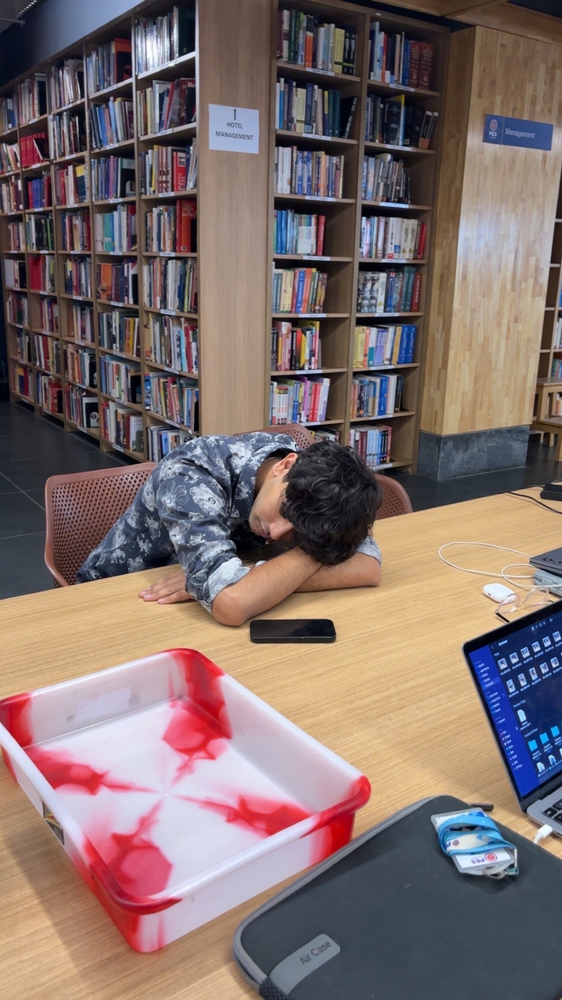

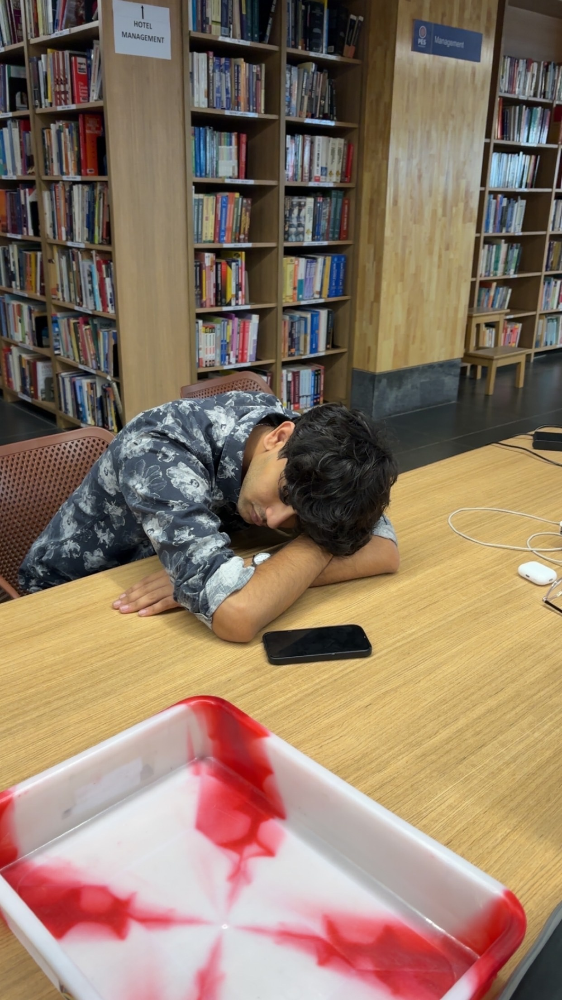

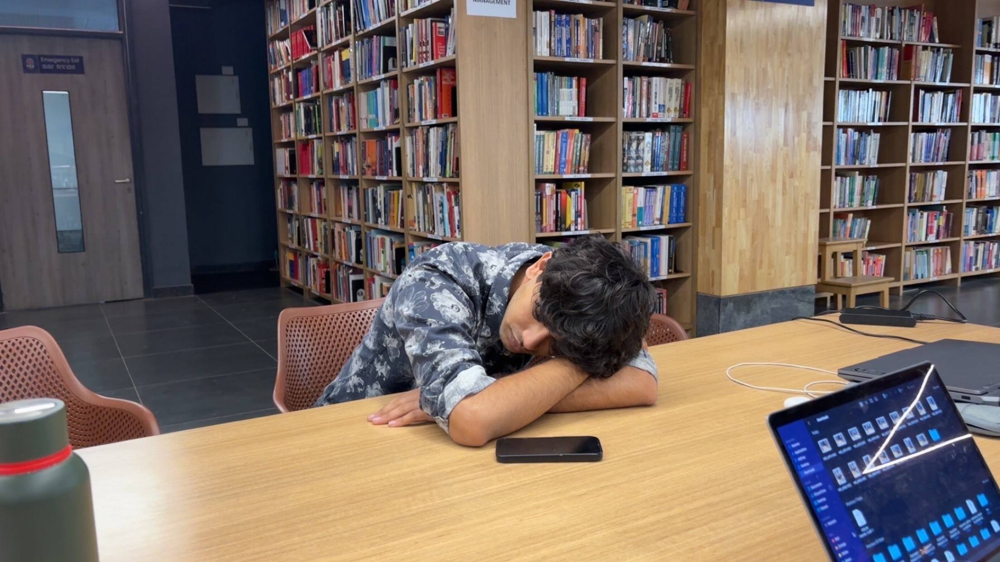

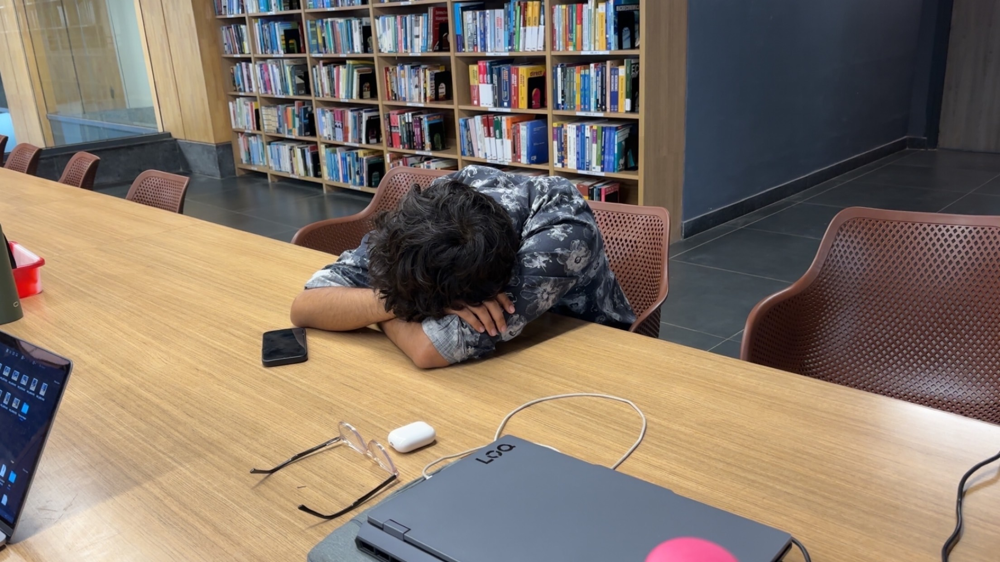

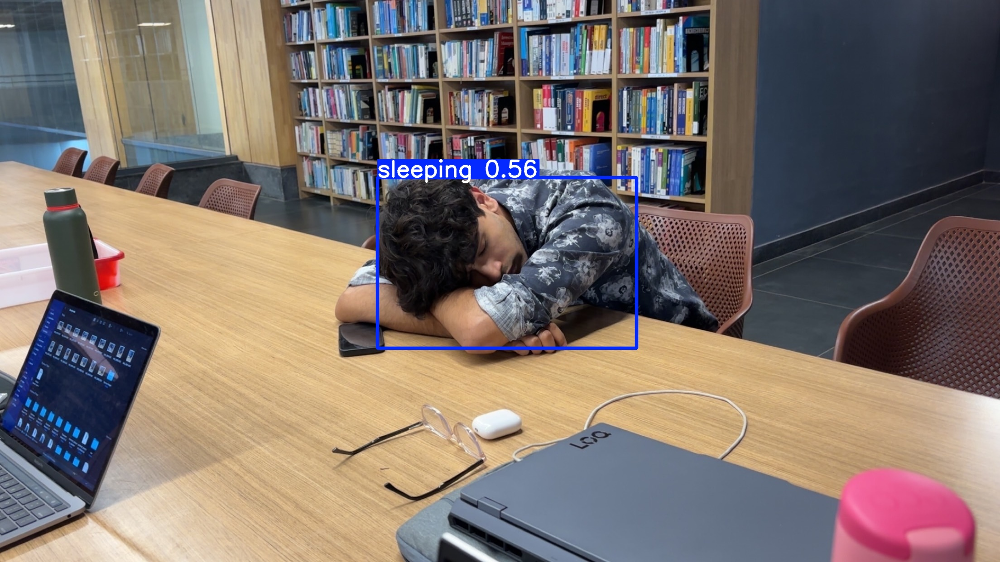

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756362866'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

Select one or more JPG/PNG images to test…


Saving IMG_4898.jpg to IMG_4898.jpg
Saving IMG_4899.jpg to IMG_4899.jpg
Saving IMG_4900.jpg to IMG_4900.jpg
Saving IMG_4901.jpg to IMG_4901.jpg
Saving IMG_4902.jpg to IMG_4902.jpg


In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)


image 1/5 /content/my_tests/IMG_4898.jpg: 384x640 1 phone_usage, 10.2ms
image 2/5 /content/my_tests/IMG_4899.jpg: 384x640 1 sleeping, 8.5ms
image 3/5 /content/my_tests/IMG_4900.jpg: 384x640 (no detections), 8.9ms
image 4/5 /content/my_tests/IMG_4901.jpg: 384x640 1 sleeping, 8.5ms
image 5/5 /content/my_tests/IMG_4902.jpg: 384x640 1 sleeping, 8.5ms
Speed: 2.2ms preprocess, 8.9ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363068
Annotated images saved to: /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363068


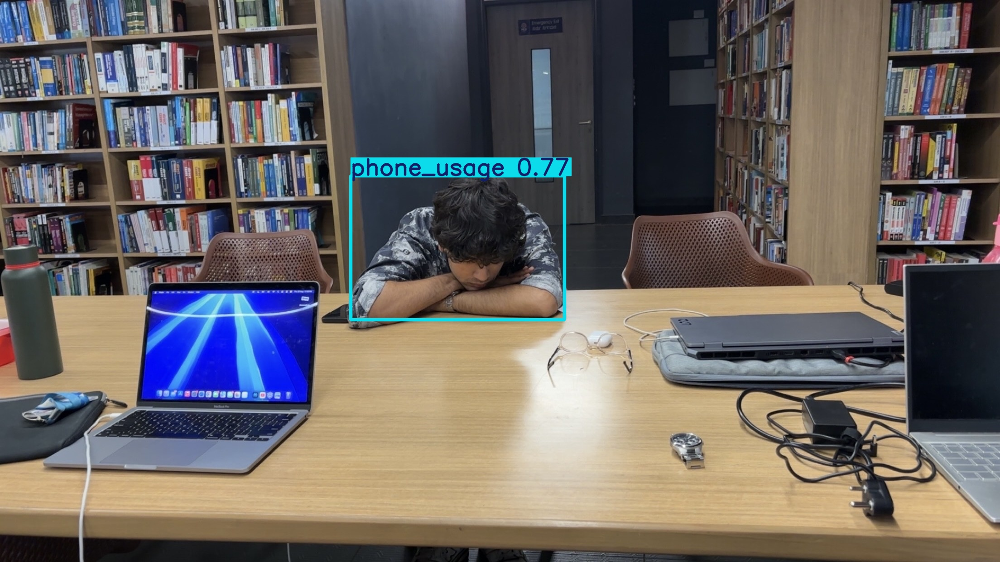

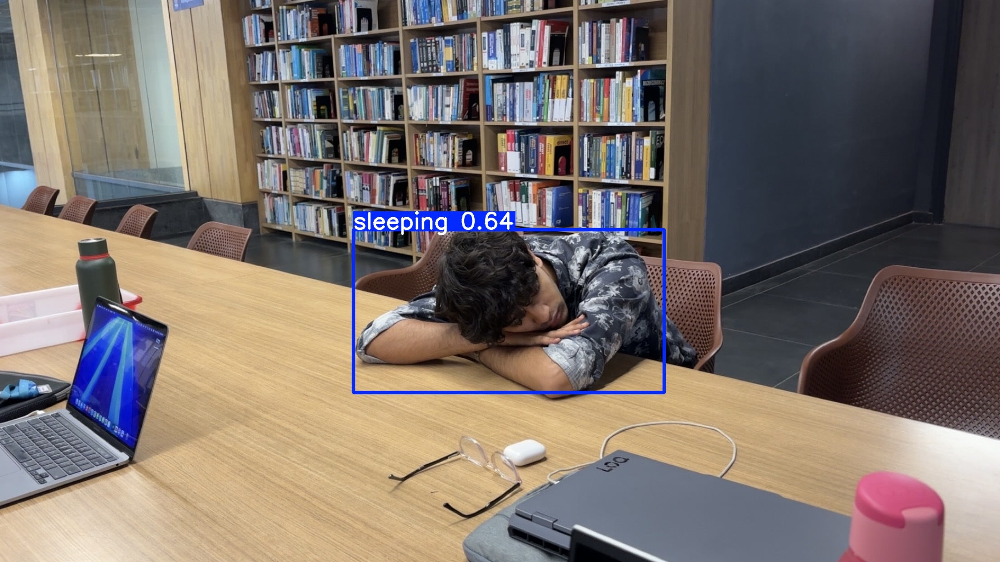

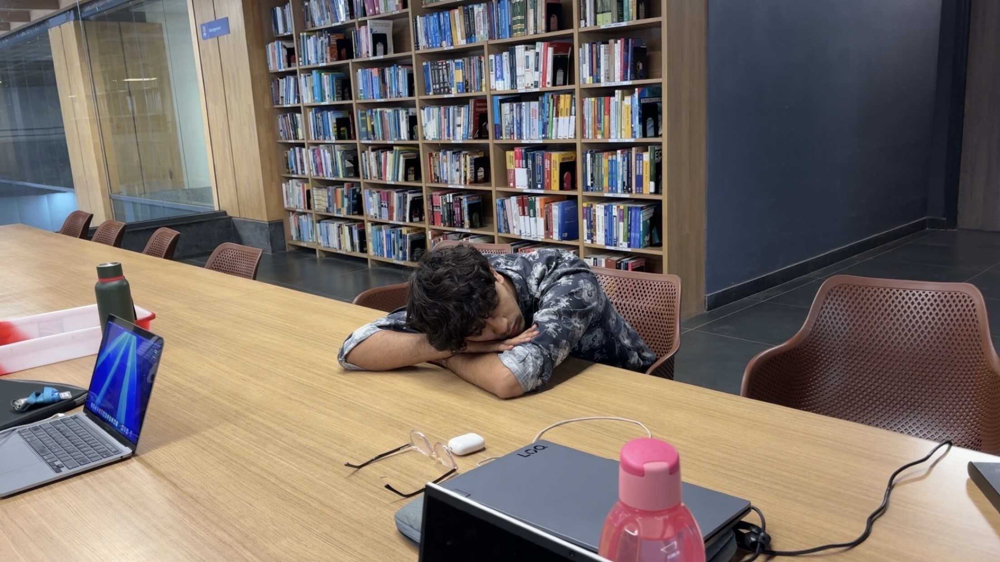

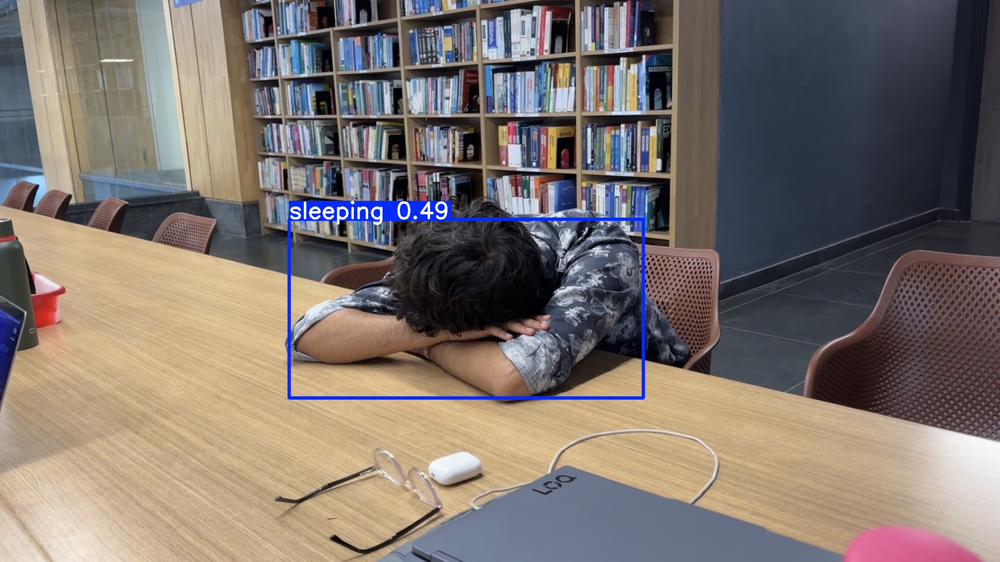

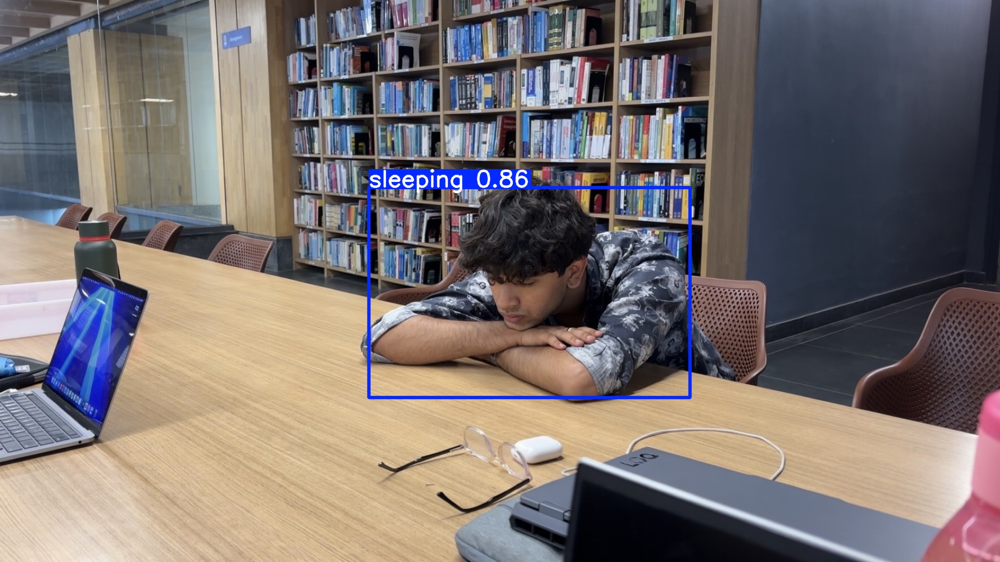

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363068'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1755851062'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

Select one or more JPG/PNG images to test…


Saving IMG_4896.JPG to IMG_4896.JPG
Saving IMG_4897.jpg to IMG_4897.jpg
Saving IMG_4898.jpg to IMG_4898.jpg


In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)


image 1/3 /content/my_tests/IMG_4896.JPG: 640x384 1 phone_usage, 10.5ms
image 2/3 /content/my_tests/IMG_4897.jpg: 384x640 1 phone_usage, 9.6ms
image 3/3 /content/my_tests/IMG_4898.jpg: 384x640 1 phone_usage, 9.0ms
Speed: 2.3ms preprocess, 9.7ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363150
Annotated images saved to: /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363150


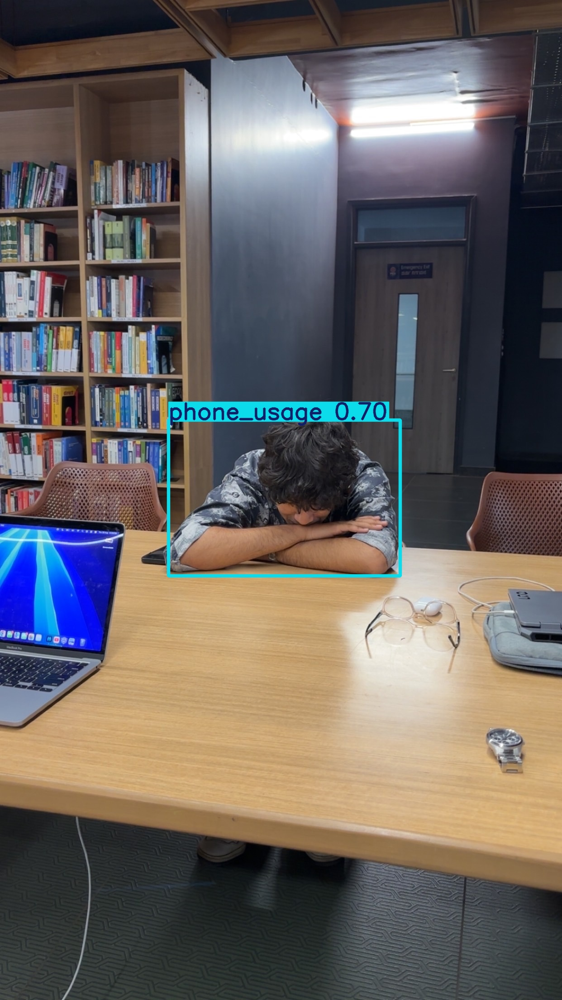

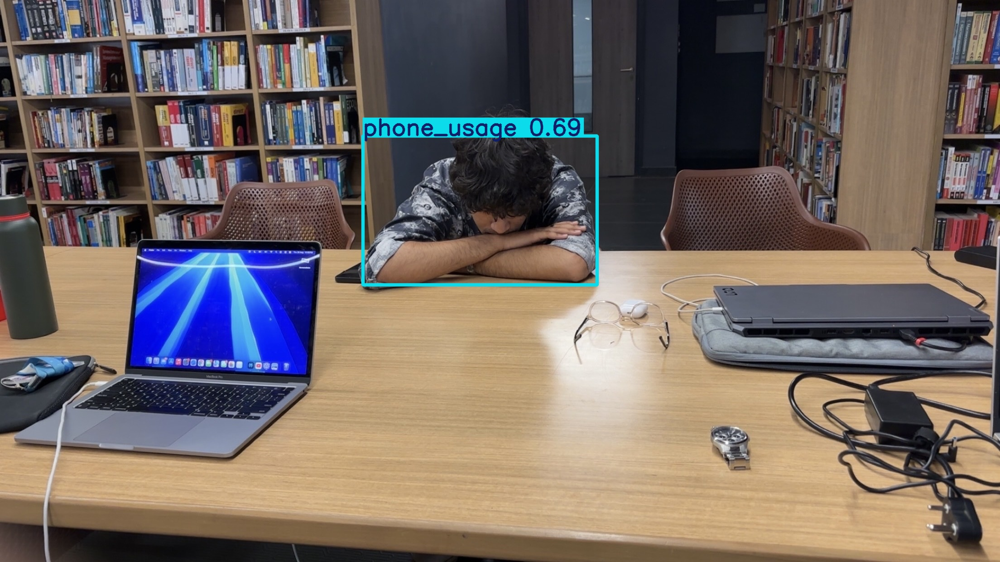

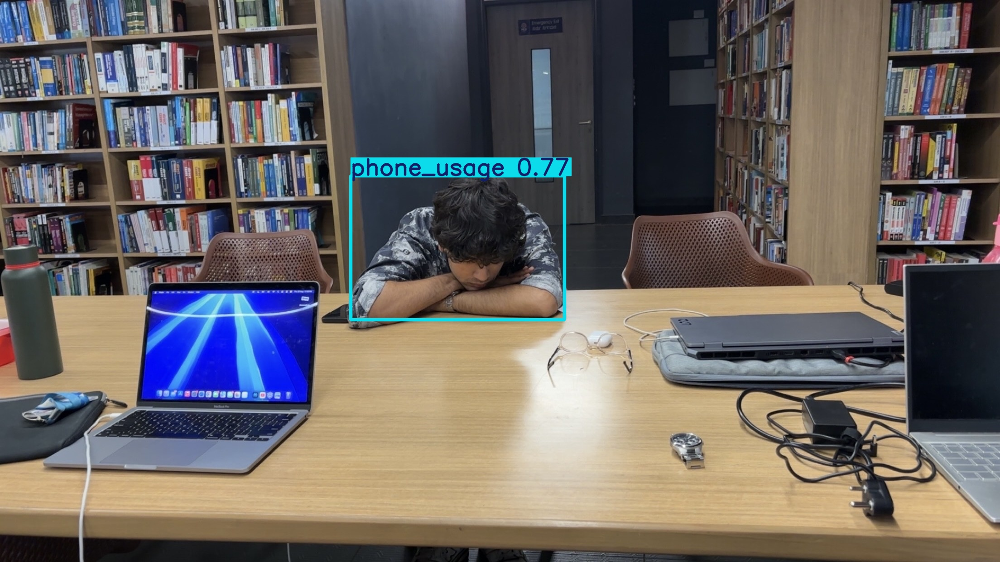

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363150'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

Select one or more JPG/PNG images to test…


Saving IMG_4904.jpg to IMG_4904.jpg
Saving IMG_4905.jpg to IMG_4905.jpg
Saving IMG_4906.jpg to IMG_4906.jpg
Saving IMG_4907.JPG to IMG_4907.JPG
Saving IMG_4908.jpg to IMG_4908.jpg


In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)


image 1/5 /content/my_tests/IMG_4904.jpg: 384x640 (no detections), 10.1ms
image 2/5 /content/my_tests/IMG_4905.jpg: 384x640 (no detections), 8.5ms
image 3/5 /content/my_tests/IMG_4906.jpg: 384x640 (no detections), 8.9ms
image 4/5 /content/my_tests/IMG_4907.JPG: 640x384 (no detections), 9.2ms
image 5/5 /content/my_tests/IMG_4908.jpg: 384x640 (no detections), 9.1ms
Speed: 2.3ms preprocess, 9.2ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363426
Annotated images saved to: /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363426


In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1755851286'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

Select one or more JPG/PNG images to test…


Saving IMG_4909.jpg to IMG_4909.jpg
Saving IMG_4910.jpg to IMG_4910.jpg
Saving IMG_4911.jpg to IMG_4911.jpg
Saving IMG_4912.jpg to IMG_4912.jpg
Saving IMG_4913.jpg to IMG_4913.jpg


In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)


image 1/5 /content/my_tests/IMG_4909.jpg: 384x640 (no detections), 10.1ms
image 2/5 /content/my_tests/IMG_4910.jpg: 384x640 1 phone_usage, 9.2ms
image 3/5 /content/my_tests/IMG_4911.jpg: 384x640 1 phone_usage, 9.2ms
image 4/5 /content/my_tests/IMG_4912.jpg: 384x640 1 phone_usage, 9.1ms
image 5/5 /content/my_tests/IMG_4913.jpg: 384x640 (no detections), 9.4ms
Speed: 2.4ms preprocess, 9.4ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363460
Annotated images saved to: /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363460


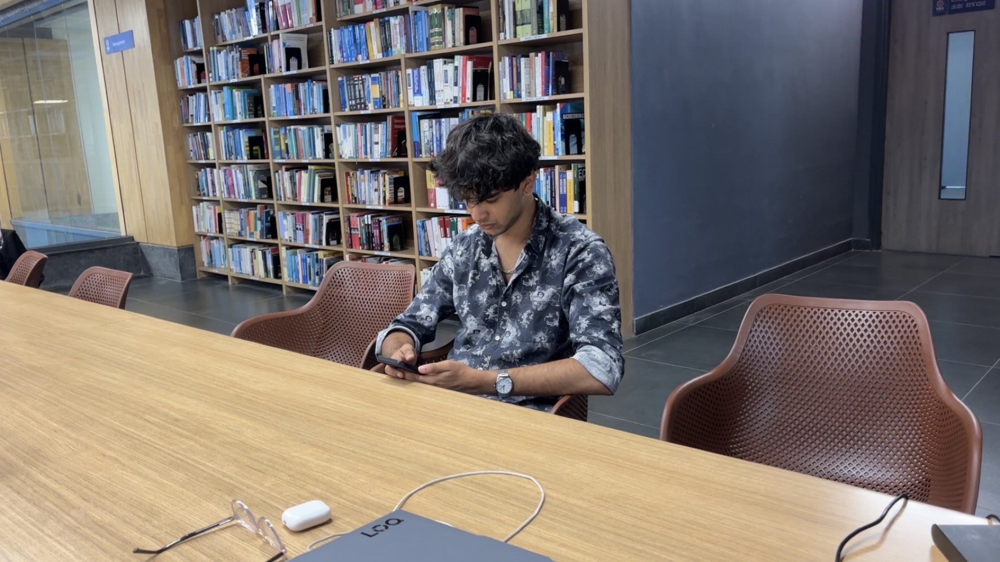

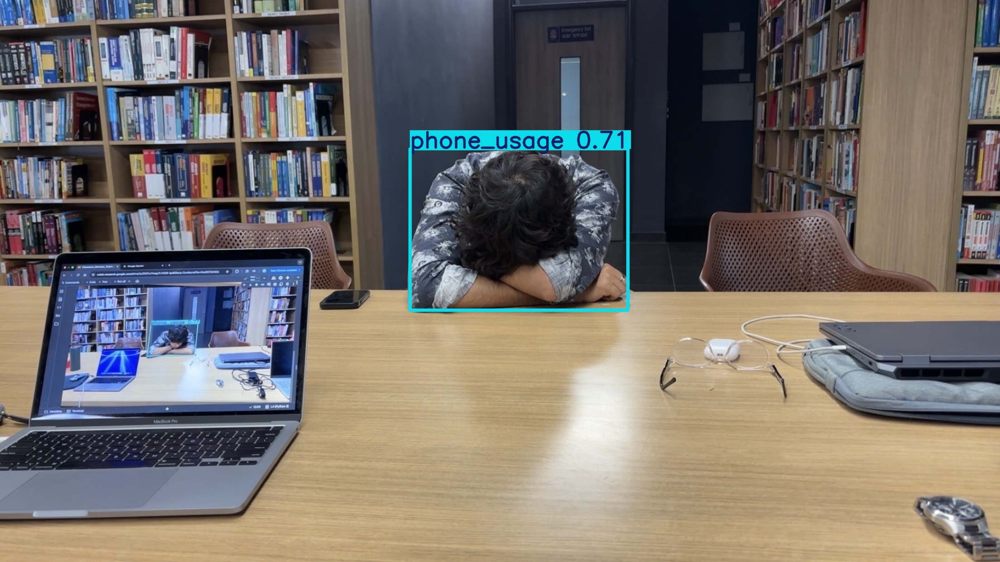

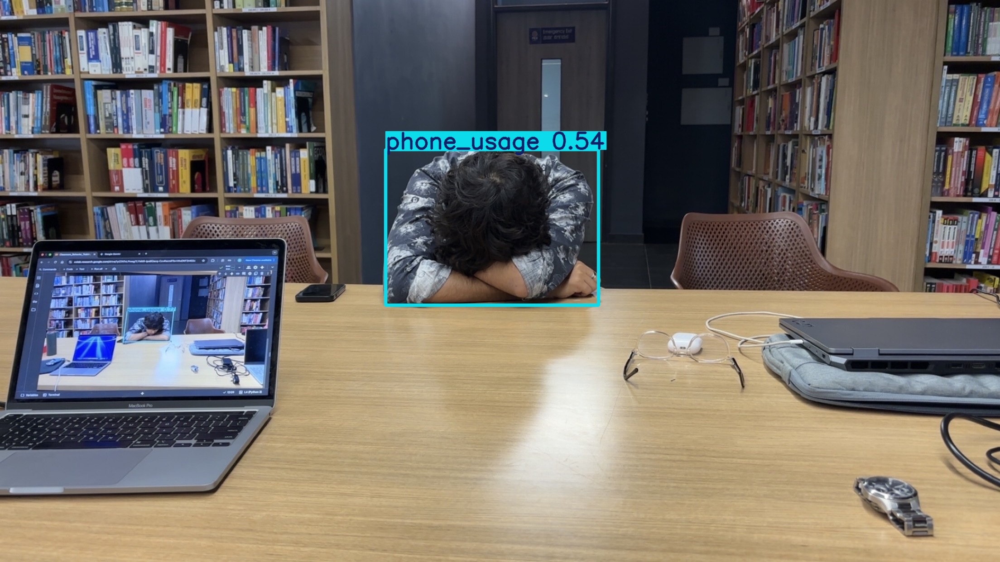

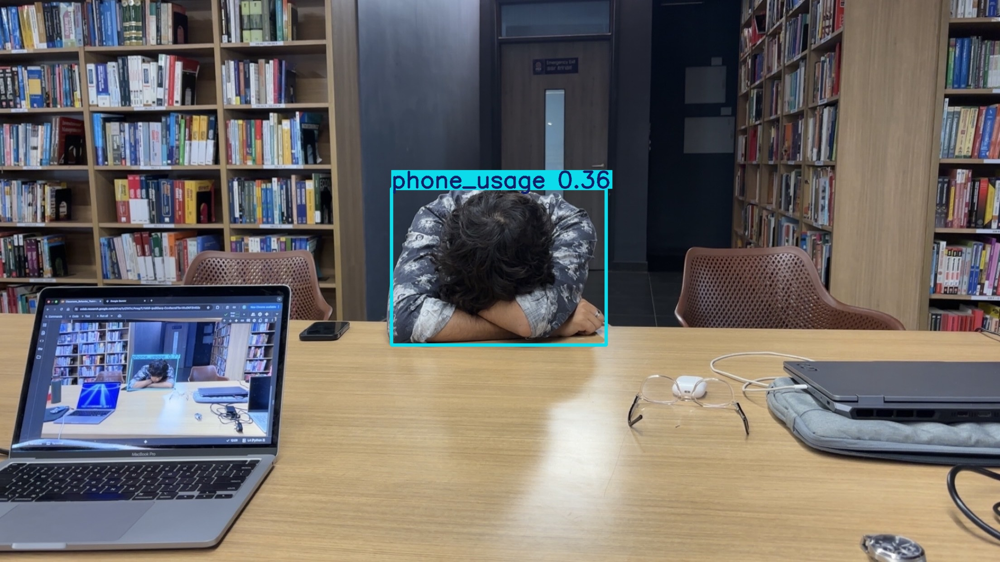

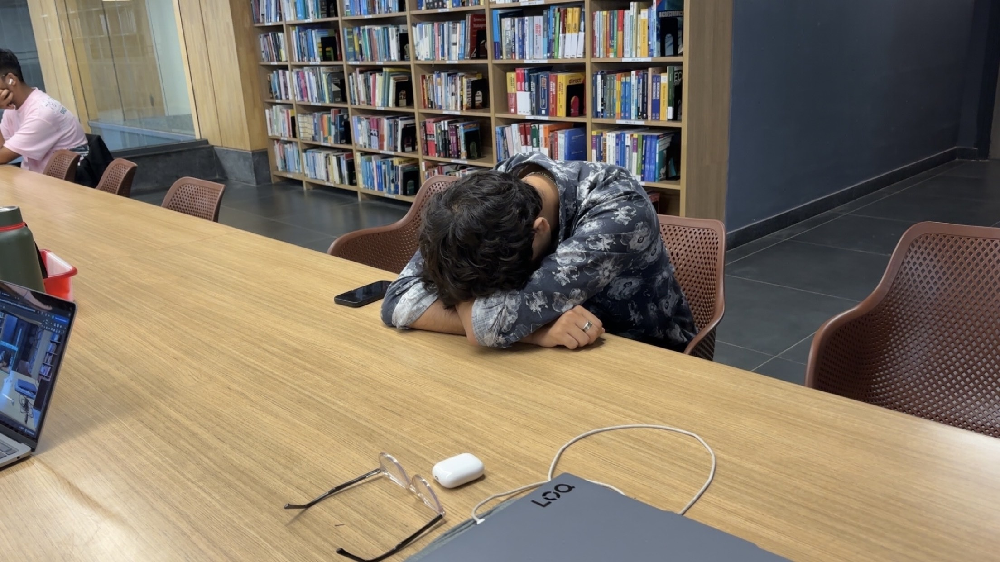

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363460'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

Select one or more JPG/PNG images to test…


Saving IMG_4912.jpg to IMG_4912.jpg
Saving IMG_4913.jpg to IMG_4913.jpg
Saving IMG_4914.jpg to IMG_4914.jpg
Saving IMG_4916.jpg to IMG_4916.jpg
Saving IMG_4917.jpg to IMG_4917.jpg


In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)


image 1/5 /content/my_tests/IMG_4912.jpg: 384x640 1 phone_usage, 9.9ms
image 2/5 /content/my_tests/IMG_4913.jpg: 384x640 (no detections), 8.5ms
image 3/5 /content/my_tests/IMG_4914.jpg: 384x640 (no detections), 8.5ms
image 4/5 /content/my_tests/IMG_4916.jpg: 384x640 (no detections), 8.4ms
image 5/5 /content/my_tests/IMG_4917.jpg: 384x640 (no detections), 8.6ms
Speed: 2.2ms preprocess, 8.8ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363521
Annotated images saved to: /content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363521


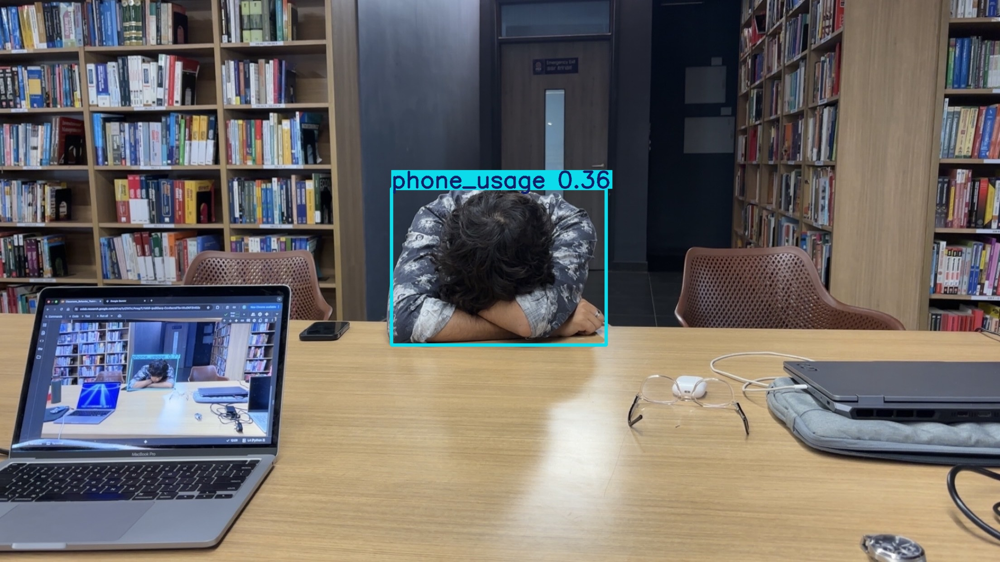

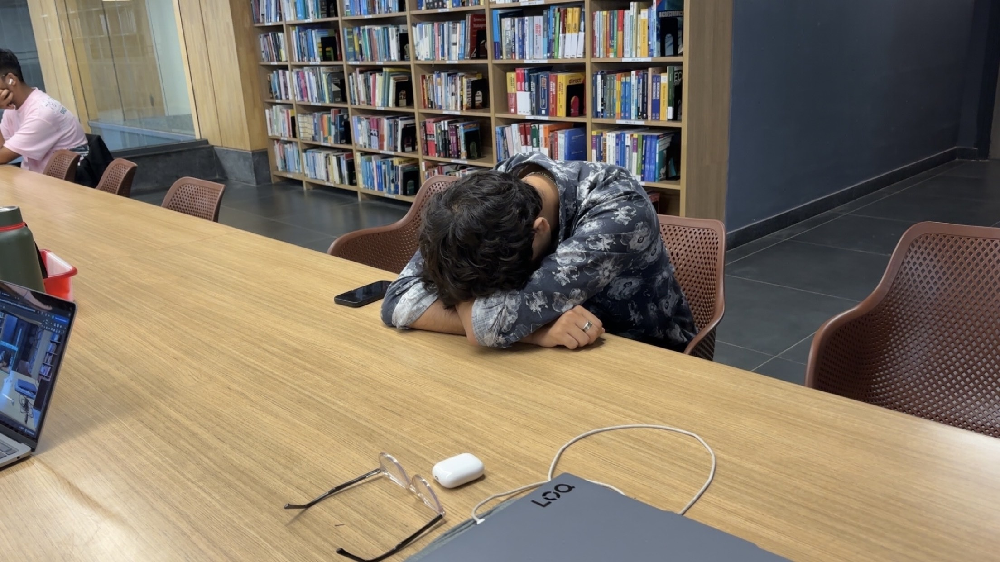

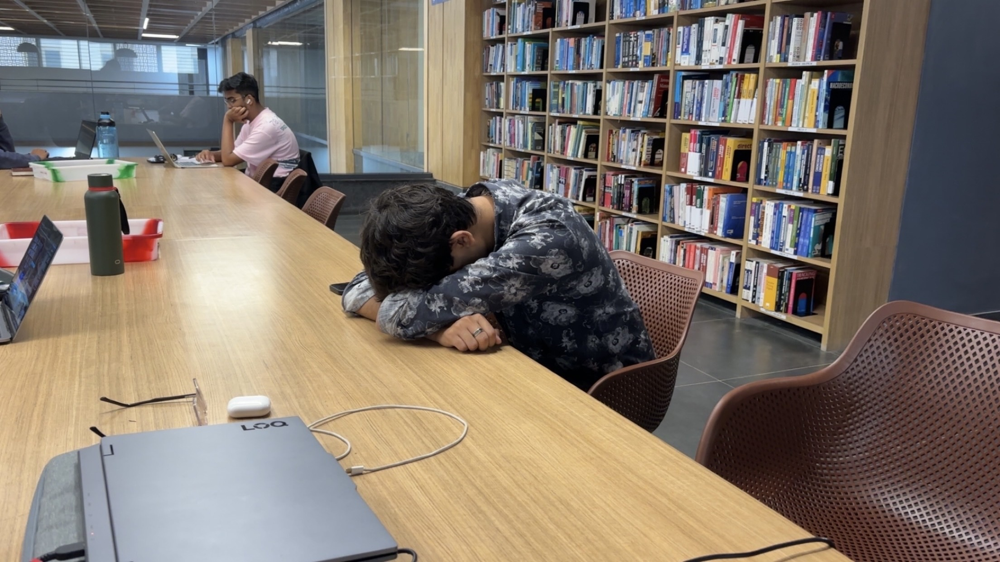

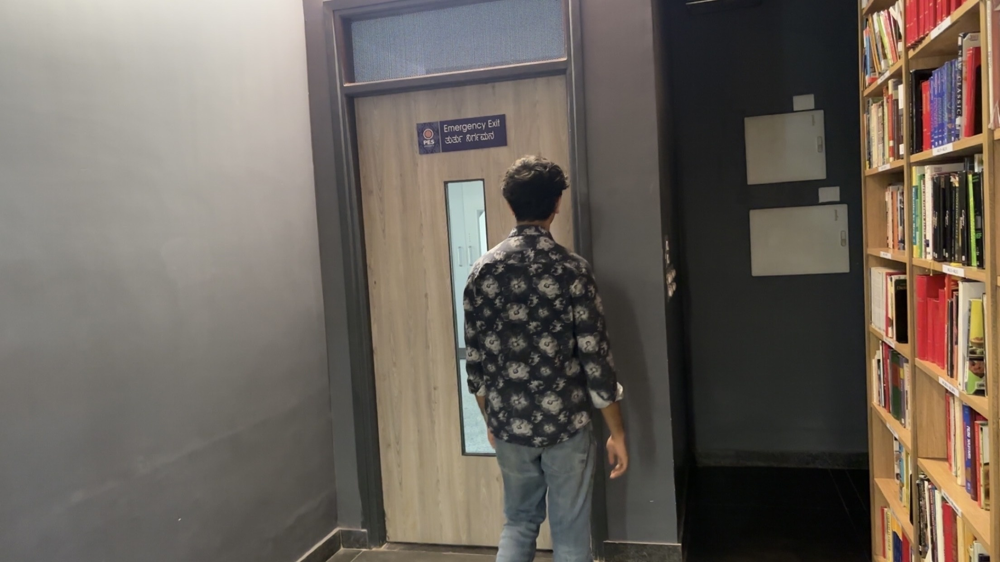

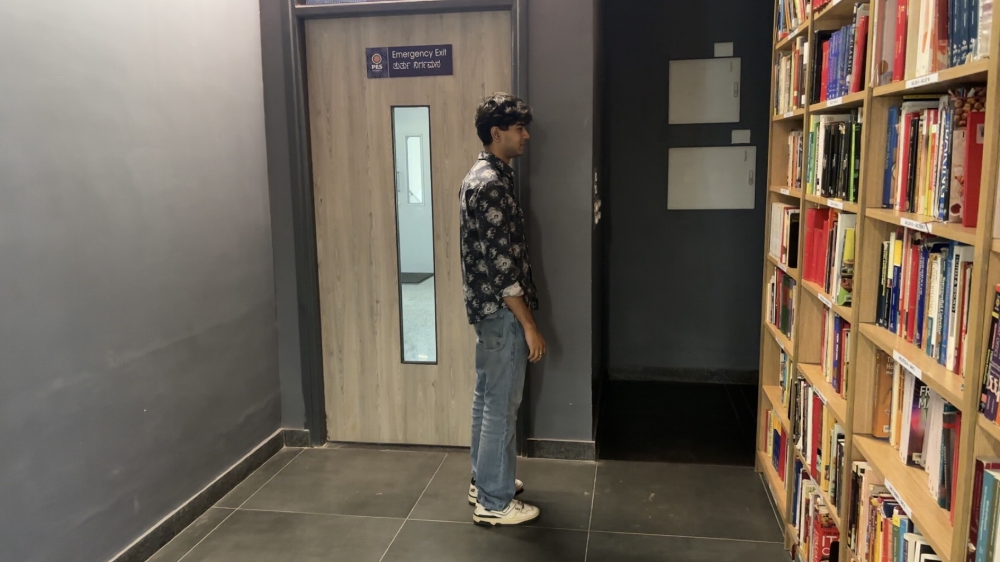

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756363521'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1755851752'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1755851910'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
from ultralytics import YOLO
from google.colab import files
import os, shutil, glob, time

In [ ]:
%pip install -q ultralytics

from ultralytics import YOLO
from google.colab import drive, files
import os, glob, shutil, time

In [ ]:
drive.mount('/content/drive')

In [ ]:
from ultralytics import YOLO
from google.colab import files
import os, shutil, glob, time

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
drive.mount('/content/drive')

In [ ]:
from ultralytics import YOLO
from google.colab import files
import os, shutil, glob, time

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
%pip install -q ultralytics

from ultralytics import YOLO
from google.colab import drive, files
import os, glob, shutil, time

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

results = model.predict(
    source=UPLOAD_DIR,  # your folder with images
    imgsz=640,
    conf=0.25,
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

In [ ]:
from ultralytics import YOLO

In [ ]:
model = YOLO('yolov8n.pt')

In [ ]:
drive.mount('/content/drive')

In [ ]:
%pip install -q ultralytics

from ultralytics import YOLO
from google.colab import drive, files
import os, glob, shutil, time

In [ ]:
BASE_DIR = '/content/drive/MyDrive/YOLOv8_Training'   # where your training runs/checkpoints live
PRED_DIR = f'{BASE_DIR}/predictions'                  # where predictions will be saved
os.makedirs(BASE_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)
print('BASE_DIR:', BASE_DIR)
print('PRED_DIR:', PRED_DIR)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, shutil, time

BASE_DIR = '/content/drive/MyDrive/YOLOv8_Training'
PRED_DIR = f'{BASE_DIR}/predictions'
os.makedirs(PRED_DIR, exist_ok=True)

def pick_latest(paths):
    paths = [p for p in paths if os.path.exists(p)]
    if not paths:
        return None
    return max(paths, key=os.path.getmtime)  # newest by modified time

def find_checkpoint():
    # look in Drive first
    best = glob.glob(f'{BASE_DIR}/**/best.pt', recursive=True)
    last = glob.glob(f'{BASE_DIR}/**/last.pt', recursive=True)
    ckpt = pick_latest(best) or pick_latest(last)
    if ckpt:
        return ckpt
    # fallback: try local runtime if anything landed under /content/runs
    local = pick_latest(glob.glob('/content/runs/**/best.pt', recursive=True)) \
            or pick_latest(glob.glob('/content/runs/**/last.pt', recursive=True))
    if local:
        recov = f'{BASE_DIR}/recovered_{int(time.time())}.pt'
        os.makedirs(BASE_DIR, exist_ok=True)
        shutil.copy2(local, recov)
        return recov
    return None

WEIGHTS = find_checkpoint()
print('Using checkpoint:', WEIGHTS)
assert isinstance(WEIGHTS, str) and os.path.exists(WEIGHTS), 'No checkpoint file found.'

from ultralytics import YOLO
model = YOLO(WEIGHTS)
print('Model loaded.')

In [ ]:
from ultralytics import YOLO
from google.colab import files
import os, shutil, glob, time

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756361579'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756361866'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756361866'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756362189'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756361866'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
import glob
from IPython.display import Image, display

out_dir = '/content/drive/MyDrive/YOLOv8_Training/predictions/images_upload_run_1756362425'
imgs = sorted(glob.glob(out_dir + '/*.jpg') + glob.glob(out_dir + '/*.png'))
for p in imgs[:5]:  # show first 5
    display(Image(filename=p))

In [ ]:
UPLOAD_DIR = '/content/my_tests'
shutil.rmtree(UPLOAD_DIR, ignore_errors=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

print('Select one or more JPG/PNG images to test…')
uploaded = files.upload()
for fname in uploaded.keys():
    shutil.move(fname, os.path.join(UPLOAD_DIR, os.path.basename(fname)))

In [ ]:
PRED_DIR = '/content/drive/MyDrive/YOLOv8_Training/predictions'
os.makedirs(PRED_DIR, exist_ok=True)
run_name = f'images_upload_run_{int(time.time())}'

pred = model.predict(
    source=UPLOAD_DIR,
    imgsz=640,
    conf=0.25,   # raise to 0.35–0.5 to reduce false positives
    iou=0.45,
    device=0,
    save=True,
    project=PRED_DIR,
    name=run_name,
    exist_ok=True
)

out_dir = f'{PRED_DIR}/{run_name}'
print('Annotated images saved to:', out_dir)

In [ ]:
from ultralytics import YOLO
import cv2
import numpy as np

model = YOLO('yolov8n.pt')
# assume `frames` is a list/iterator of numpy arrays acquired via the JS helper
for frame in frames:
    results = model.predict(source=frame, imgsz=640, conf=0.25, verbose=False)
    annotated = results.plot()
    # display inline in Colab
    _, buf = cv2.imencode('.jpg', annotated)
    display(Image(data=buf.tobytes()))

NameError: name 'frames' is not defined

In [ ]:
# Cell 1 — JS webcam -> Python generator
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import numpy as np
import cv2

def webcam_frames(quality=0.8):
    js = Javascript("""
    async function streamWebcam(quality) {
      const video = document.createElement('video');
      const btn = document.createElement('button');
      btn.textContent = 'Stop';
      const stream = await navigator.mediaDevices.getUserMedia({video:true});
      document.body.appendChild(video); document.body.appendChild(btn);
      video.srcObject = stream; await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      let canvas = document.createElement('canvas'), ctx = canvas.getContext('2d');
      while (true){
        await new Promise(r => requestAnimationFrame(r));
        if (btn.clicked) break;
        canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        ctx.drawImage(video,0,0);
        let data = canvas.toDataURL('image/jpeg', quality);
        await google.colab.kernel.invokeFunction('pycb', [data], {});
      }
      stream.getVideoTracks().stop(); video.remove(); btn.remove();
    }
    """)
    display(js)

    frames = []
    def _cb(data):
        nonlocal frames
        img = b64decode(data.split(',')[1])
        arr = np.frombuffer(img, np.uint8)
        frame = cv2.imdecode(arr, cv2.IMREAD_COLOR)
        frames.append(frame)

    from google.colab import kernels
    kernels.callable('pycb', _cb)
    eval_js('streamWebcam({})'.format(quality))
    for f in frames:
        yield f


In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display

model = YOLO('yolov8n.pt')  # or your weights
for frame in webcam_frames():
    results = model.predict(source=frame, imgsz=640, conf=0.25, verbose=False)
    annotated = results.plot()
    _, buf = cv2.imencode('.jpg', annotated)
    display(Image(data=buf.tobytes()))


<IPython.core.display.Javascript object>

ImportError: cannot import name 'kernels' from 'google.colab' (/usr/local/lib/python3.12/dist-packages/google/colab/__init__.py)

In [ ]:
# JS <-> Python webcam bridge compatible with current Colab
from IPython.display import Javascript, display
from google.colab.output import eval_js
import numpy as np, cv2, base64

def start_webcam(quality=0.8):
    js = Javascript("""
      async function setupCamera(quality){
        const video = document.createElement('video');
        const stopBtn = document.createElement('button');
        stopBtn.textContent = 'Stop';
        document.body.appendChild(video);
        document.body.appendChild(stopBtn);
        const stream = await navigator.mediaDevices.getUserMedia({video:true, audio:false});
        video.srcObject = stream; await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        let stopped = false;
        stopBtn.onclick = () => { stopped = true; };

        const canvas = document.createElement('canvas');
        const ctx = canvas.getContext('2d');
        while (!stopped){
          await new Promise(r => requestAnimationFrame(r));
          canvas.width = video.videoWidth; canvas.height = video.videoHeight;
          ctx.drawImage(video,0,0);
          const data = canvas.toDataURL('image/jpeg', quality);
          google.colab.kernel.invokeFunction('notebook.onFrame', [data], {});
        }
        stream.getVideoTracks().stop();
        video.remove(); stopBtn.remove();
        return 'stopped';
      }
    """)
    display(js)

    frames = []
    # simple callback using eval_js to start the loop and capture frames
    from google.colab import output
    def _on_frame(data_url):
        b = base64.b64decode(data_url.split(',')[1])
        arr = np.frombuffer(b, dtype=np.uint8)
        frame = cv2.imdecode(arr, cv2.IMREAD_COLOR)
        frames.append(frame)

    output.register_callback('notebook.onFrame', _on_frame)
    eval_js("setupCamera({})".format(quality))

    # yield frames already collected; this runs until Stop is pressed
    for f in frames:
        yield f